# Features Engineering
Phần này sẽ giải quyết việc chọn các feature như thế nào cho phù hợp và tối ưu để huấn luyện model.

Các chiến thuật Tạo mới đặc trưng mới, biến đổi đặc trưng

Chọn lựa đặc trưng: 

   - Dùng các mô hình máy học LASSO, Ridge, ElasticNet, Decision Tree, Random Forest để tìm các đặc trưng quan trọng

   - Dựa trên phân tích thống kê ở bước EDA

   - Chiến thuật để bỏ đặc trưng

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import os
import tensorflow as tf
from sklearn.preprocessing import OrdinalEncoder
import lightgbm as lgb
import os, sys, gc, time, warnings, pickle, psutil, random
from tqdm import tqdm
from math import ceil
from sklearn.preprocessing import LabelEncoder
import math
from statsmodels.tsa.seasonal import STL
from scipy import stats
from lightgbm import early_stopping, log_evaluation
import pandas as pd
from sklearn.linear_model import Lasso
from sklearn.model_selection import train_test_split, GridSearchCV
import seaborn as sns
print("Num GPUs Available:", len(tf.config.experimental.list_physical_devices('GPU')))
print("GPU Details:", tf.config.experimental.list_physical_devices('GPU'))

Num GPUs Available: 1
GPU Details: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 🔍 Tạo đặc trưng thời gian từ dữ liệu demand

Để mô hình dự đoán chính xác hơn, ta tạo ra các đặc trưng từ dữ liệu quá khứ, đồng thời mong muốn học được món hàng đang được dự đoán có đang nằm gần hoặc trong xu hướng hay không:

- **Lag features**: Doanh thu tại các mốc thời gian lùi lại, ví dụ 7 hoặc 28 ngày trước. Điều này giúp mô hình nhận biết chu kỳ tuần / tháng.
- **Rolling mean features**: Trung bình động trong 7 hoặc 28 ngày gần mốc lag, giúp mô hình hiểu xu hướng tăng giảm của nhu cầu.
- Tất cả đặc trưng đều được tính theo từng `id` (mỗi sản phẩm tại từng cửa hàng cụ thể).

Hàm `demand_features(df)` sẽ tự động tạo ra các cột này để sử dụng trong huấn luyện mô hình.

Để hiểu rõ hơn ví dụ nếu như là lag_t7 cho ngày thứ 100 của món hàng A sẽ là doanh thu của ngày thứ 93. còn, rolling_mean_lag7_w28 của ngày thứ 100 của món hàng A sẽ là doanh thu trung bình từ ngày 72 (=100 - 28) tới ngày 78 (7 ngày).


In [2]:
calendar = pd.read_parquet('done_cal.parquet')
sales = pd.read_parquet('done_sales.parquet')
prices = pd.read_parquet('done_prices.parquet')

In [3]:
LAGS = [7, 28]
WINDOWS = [7, 28]
FIRST = 1942 # first to predict
LENGTH = 28

def demand_features(df):
    """ Derive features from sales data and remove rows with missing values """

    for lag in LAGS:
        df[f'lag_t{lag}'] = df.groupby('id')['demand'].transform(lambda x: x.shift(lag)).astype("float32")
        for w in WINDOWS:
            df[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id')[f'lag_t{lag}'].transform(lambda x: x.rolling(w).mean()).astype("float32")

    return df

def demand_features_eval(df):
    """ Same as demand_features but for the step-by-step evaluation """
    out = df.groupby('id', sort=False).last()
    for lag in LAGS:
        out[f'lag_t{lag}'] = df.groupby('id', sort=False)['demand'].nth(-lag-1).astype("float32")
        for w in WINDOWS:
            out[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id', sort=False)['demand'].nth(list(range(-lag-w, -lag))).groupby('id', sort=False).mean().astype("float32")

    return out.reset_index()

def prep_data(df, drop_d=1000):
    """ Prepare model data sets """

    # Kick out old dates
    df = df.drop(["d_" + str(i+1) for i in range(drop_d)], axis=1)

    # Reshape to long
    df = df.assign(id=df.id.str.replace("_evaluation", ""))
    df = df.reindex(columns=df.columns.tolist() + ["d_" + str(FIRST + i) for i in range(LENGTH)])
    df = df.melt(id_vars=["id", "item_id", "store_id", "state_id", "dept_id", "cat_id"], var_name='d', value_name='demand')
    df = df.assign(d=df.d.str[2:].astype("int64"),
                   demand=df.demand.astype("float32"))

    # Add demand features
    df = demand_features(df)

    # Remove rows with NAs
    df = df[df.d > (drop_d + max(LAGS) + max(WINDOWS))]

    # Join calendar & prices
    df = df.merge(calendar, how="left", on="d")
    df = df.merge(prices, how="left", on=["store_id", "item_id", "wm_yr_wk"])
    df = df.drop(["wm_yr_wk"], axis=1)

    # Ordinal encoding of remaining categorical fields
    for v in ["item_id", "store_id", "state_id", "dept_id", "cat_id"]:
        df[v] = OrdinalEncoder(dtype="int").fit_transform(df[[v]]).astype("int16") + 1

    # Determine list of covariables
    x = list(set(df.columns) - {'id', 'd', 'demand'})

    # Split into test, valid, train
    test = df[df.d >= FIRST - max(LAGS) - max(WINDOWS) - 28]
    df = df[df.d < FIRST]

    return df, test, x

df, test, x = prep_data(sales, 1000 - 28)

In [4]:
del sales, prices, calendar,test
gc.collect()

0

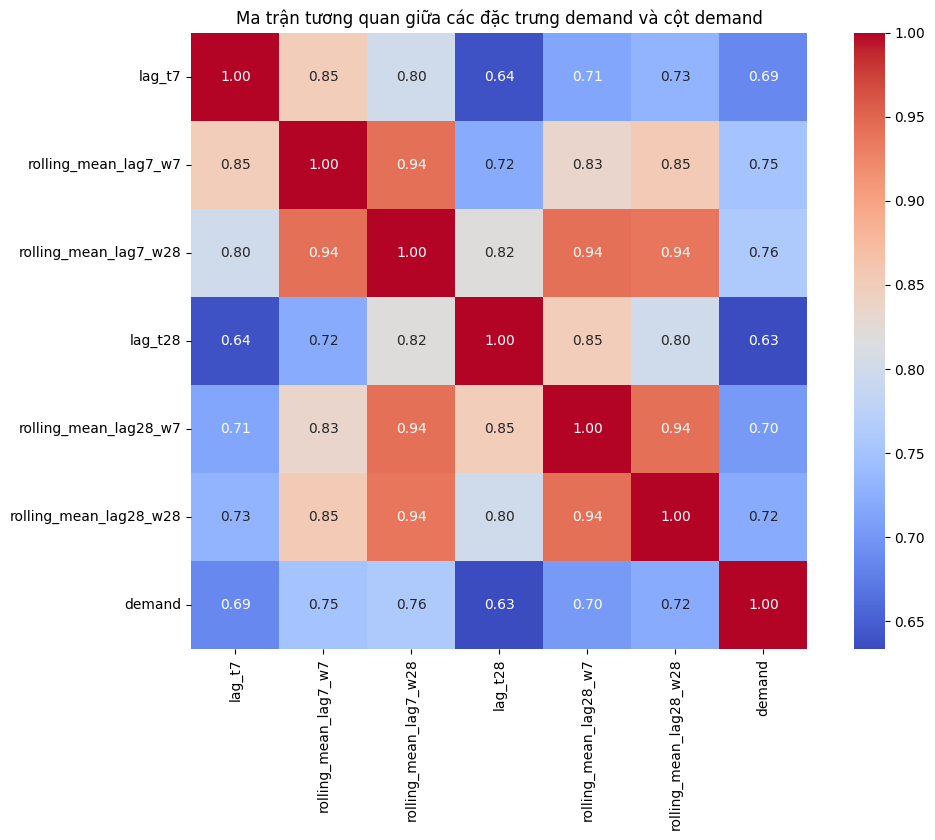

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_demand_feature_correlation(df):
    # Lấy danh sách các cột được tạo bởi demand_features
    demand_cols = [col for col in df.columns if col.startswith("lag_t") or col.startswith("rolling_mean")]

    # Thêm cột demand để so sánh tương quan
    corr_cols = demand_cols + ["demand"]

    # Loại bỏ hàng có NaN (do shift và rolling tạo ra)
    df_corr = df[corr_cols].dropna()

    # Tính ma trận tương quan
    corr = df_corr.corr()

    # Vẽ heatmap
    plt.figure(figsize=(12, 8))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
    plt.title("Ma trận tương quan giữa các đặc trưng demand và cột demand")
    plt.show()
plot_demand_feature_correlation(df)

## Nhận xét ma trận tương quan
Thông qua, ma trận dễ dàng thấy demand ảnh hưởng khá nhiều bởi các feature đã được tạo ra. Tuy nhiên, cũng có thể thấy các cột rolling_mean có độ tương quan cao khi bắt cặp với nhau.

Dựa trên, độ tương quan giữa demand và các cột rolling_mean, nhóm quyết định giữ lại rolling_mean_lag7_w7 và rolling_mean_lag7_w28 và xóa đi 2 rolling_mean còn lại vì có độ tương quan cao với 2 rolling_mean_lag7_w7 còn lại

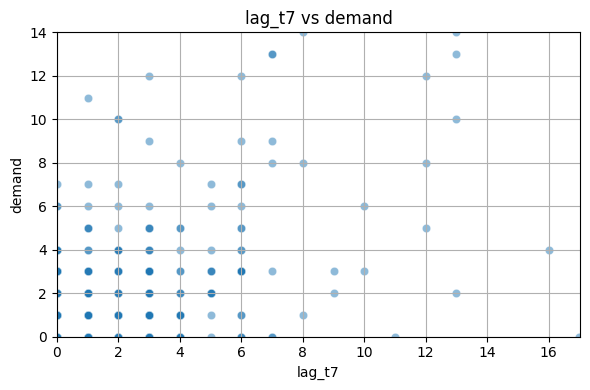

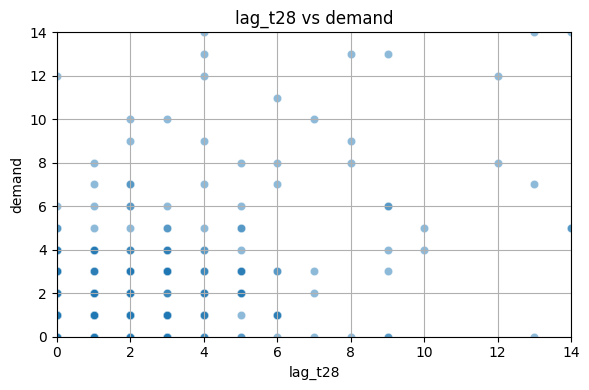

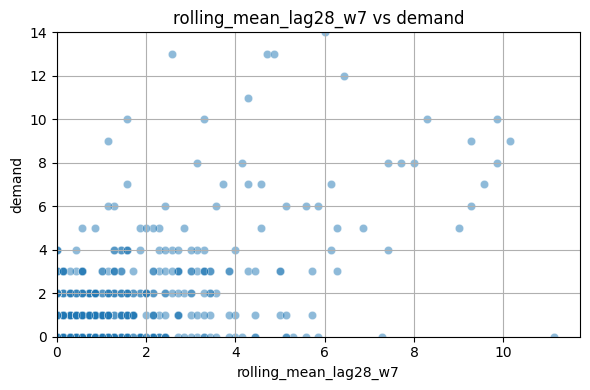

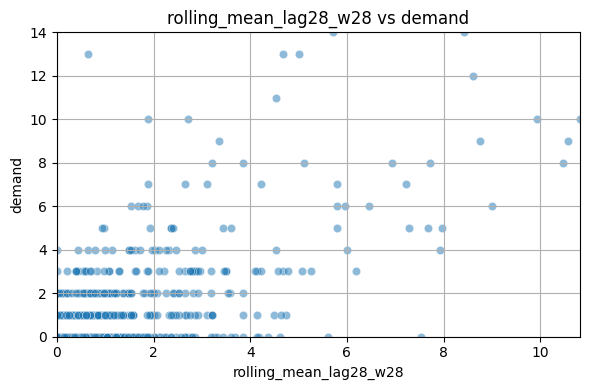

13310

In [5]:
df.drop(['rolling_mean_lag7_w7', 'rolling_mean_lag7_w28'], axis=1, inplace=True)

def plot_demand_feature_scatter(df, sample_size=1000, use_log=False, clip_outliers=True):
    import seaborn as sns
    import matplotlib.pyplot as plt

    demand_cols = [col for col in df.columns if col.startswith("lag_t") or col.startswith("rolling_mean")]
    df_sample = df[demand_cols + ["demand"]].dropna().sample(n=sample_size, random_state=42)

    for col in demand_cols:
        plt.figure(figsize=(6, 4))
        sns.scatterplot(data=df_sample, x=col, y="demand", alpha=0.5)

        if clip_outliers:
            plt.xlim(df_sample[col].quantile(0.01), df_sample[col].quantile(0.99))
            plt.ylim(df_sample["demand"].quantile(0.01), df_sample["demand"].quantile(0.99))

        if use_log:
            plt.xscale("log")
            plt.yscale("log")

        plt.title(f"{col} vs demand")
        plt.xlabel(col)
        plt.ylabel("demand")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

plot_demand_feature_scatter(df)

del df,x
gc.collect()

## Tìm kiếm thêm đặc trưng mới
Nhận thấy việc bán lẻ, các cửa hàng sẽ có xu hướng bị ảnh hưởng bởi các đặc trưng như giá vàng, sự kiến MMA, thiên tai

## 🟡 1. Giá vàng
### Giả định ảnh hưởng:

- Giá vàng thường được xem như một chỉ báo kinh tế. Khi giá vàng tăng mạnh, nó thường phản ánh tâm lý bất ổn kinh tế, khiến người dân tiết kiệm hơn —> giảm chi tiêu ở siêu thị.

- Ngược lại, giá vàng giảm có thể khiến người dân thấy kinh tế ổn định hơn —> tăng chi tiêu.

### Cách kiểm chứng dữ liệu:

- Lấy dữ liệu giá vàng hàng ngày hoặc hàng tuần.

- Kết hợp với dữ liệu bán hàng theo thời gian.

In [13]:
df = pd.read_parquet('../../data/train_val.parquet').head(1000000)
print(df.columns)
# print(df['date'].unique())


Index(['id', 'item_id', 'store_id', 'state_id', 'dept_id', 'cat_id', 'd',
       'demand', 'lag_t7', 'rolling_mean_lag7_w7', 'rolling_mean_lag7_w28',
       'lag_t28', 'rolling_mean_lag28_w7', 'rolling_mean_lag28_w28', 'date',
       'wday', 'month', 'year', 'event_name_1', 'event_name_2', 'snap_CA',
       'snap_TX', 'snap_WI', 'sell_price', 'disaster_type',
       'disaster_severity_flag', 'flag_ufc', 'gold_price', 'humidity'],
      dtype='object')


In [14]:
print(df['state_id'].unique())

[1 2 3]


In [15]:
import pandas as pd
import numpy as np

def fill_gold_price_with_rolling_mean(df):
    df = df.copy()
    
    for i in range(len(df)):
        # Kiểm tra nếu giá trị là null hoặc bằng 0
        if pd.isna(df.loc[i, 'gold_price']) or df.loc[i, 'gold_price'] == 0:
            if i == 0:  # Trường hợp đặc biệt: hàng đầu tiên
                # Đối với hàng đầu tiên, có thể sử dụng giá trị mặc định hoặc để nguyên
                continue  # Bỏ qua và giữ nguyên giá trị
            else:
                # Lấy tối đa 7 ngày trước để tính trung bình
                start_idx = max(0, i-7)
                # Lọc những giá trị hợp lệ (không null và khác 0)
                valid_values = [df.loc[j, 'gold_price'] for j in range(start_idx, i) 
                                if not pd.isna(df.loc[j, 'gold_price']) and df.loc[j, 'gold_price'] != 0]
                
                if valid_values:  # Nếu có ít nhất một giá trị hợp lệ
                    # Tính trung bình và gán
                    df.loc[i, 'gold_price'] = sum(valid_values) / len(valid_values)
                elif i > 0:  # Nếu không có giá trị hợp lệ nhưng có hàng trước đó
                    # Sử dụng giá trị của hàng liền trước (nếu có)
                    df.loc[i, 'gold_price'] = df.loc[i-1, 'gold_price']
    
    return df

# Gọi hàm
df = fill_gold_price_with_rolling_mean(df)

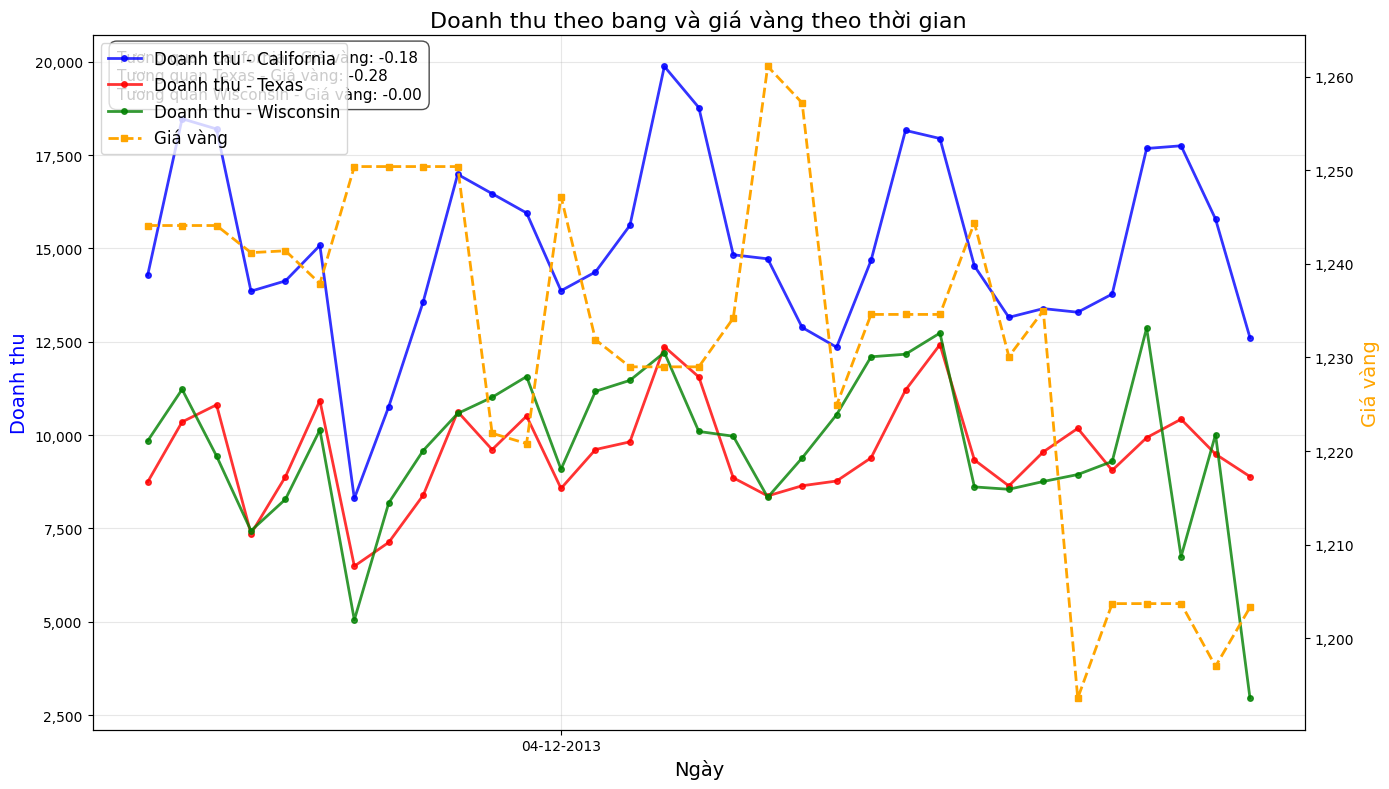

In [17]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# Chuyển đổi state_id sang tên bang
state_mapping = {
    1: 'California',
    2: 'Texas',
    3: 'Wisconsin'
}

# Thêm cột state_name vào DataFrame
df['state_name'] = df['state_id'].map(state_mapping)

# Chuyển đổi cột ngày sang định dạng datetime nếu chưa phải
df['date'] = pd.to_datetime(df['date'])

# Nhóm dữ liệu theo ngày và bang, tính tổng doanh thu cho tất cả sản phẩm
daily_revenue_by_state = df.groupby(['date', 'state_name'])['demand'].sum().unstack()

# Lấy giá vàng cho mỗi ngày (giả sử giá vàng giống nhau trong một ngày)
gold_prices = df.groupby('date')['gold_price'].first()

# Tạo một figure với 2 trục y
fig, ax1 = plt.subplots(figsize=(14, 8))

# Đặt trục y thứ hai cho giá vàng
ax2 = ax1.twinx()

# Màu sắc cho các đường doanh thu của từng bang
colors = ['blue', 'red', 'green']

# Vẽ đường doanh thu cho mỗi bang trên trục y thứ nhất
for i, state in enumerate(daily_revenue_by_state.columns):
    ax1.plot(
        daily_revenue_by_state.index,
        daily_revenue_by_state[state],
        color=colors[i],
        marker='o',
        markersize=4,
        linewidth=2,
        alpha=0.8,
        label=f'Doanh thu - {state}'
    )

# Vẽ đường giá vàng trên trục y thứ hai
ax2.plot(
    gold_prices.index,
    gold_prices.values,
    color='orange',
    marker='s',
    markersize=4,
    linewidth=2,
    linestyle='--',
    label='Giá vàng'
)

# Định dạng trục x để hiển thị label cứ mỗi 50 ngày
# Xác định ngày đầu tiên và cuối cùng trong dữ liệu
first_date = min(daily_revenue_by_state.index.min(), gold_prices.index.min())
last_date = max(daily_revenue_by_state.index.max(), gold_prices.index.max())

# Tạo một mảng các ngày với khoảng cách 50 ngày
date_range = pd.date_range(start=first_date, end=last_date, freq='50D')

# Thiết lập các vị trí và nhãn cho trục x
ax1.xaxis.set_major_locator(mdates.DayLocator(interval=50))
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%d-%m-%Y'))

# Đặt tiêu đề và nhãn
ax1.set_title('Doanh thu theo bang và giá vàng theo thời gian', fontsize=16)
ax1.set_xlabel('Ngày', fontsize=14)
ax1.set_ylabel('Doanh thu', fontsize=14, color='blue')
ax2.set_ylabel('Giá vàng', fontsize=14, color='orange')

# Xoay nhãn trục x để dễ đọc
plt.xticks(rotation=45)

# Định dạng số lớn hơn với dấu phẩy ngăn cách hàng nghìn
def thousands_formatter(x, pos):
    return f'{int(x):,}'

ax1.yaxis.set_major_formatter(FuncFormatter(thousands_formatter))
ax2.yaxis.set_major_formatter(FuncFormatter(thousands_formatter))

# Kết hợp legends từ cả hai trục
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', frameon=True, fontsize=12)

# Thêm lưới để dễ đọc
ax1.grid(True, alpha=0.3)

# Tính tương quan giữa giá vàng và doanh thu cho mỗi bang và hiển thị
corr_text = []
for state in daily_revenue_by_state.columns:
    # Kết hợp dữ liệu để tính toán tương quan
    state_data = pd.DataFrame({
        'revenue': daily_revenue_by_state[state],
        'gold_price': gold_prices
    }).dropna()

    corr = state_data['revenue'].corr(state_data['gold_price'])
    corr_text.append(f'Tương quan {state} - Giá vàng: {corr:.2f}')

# Hiển thị thông tin tương quan ở góc trái trên
ax1.annotate(
    '\n'.join(corr_text),
    xy=(0.02, 0.98),
    xycoords='axes fraction',
    va='top',
    ha='left',
    fontsize=11,
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.7)
)

plt.tight_layout()
plt.show()

## 🥋 2. Sự kiện MMA
### Giả định ảnh hưởng:

- Các sự kiện thể thao lớn (đặc biệt là UFC, WWE...) thường dẫn tới mua sắm trước sự kiện như đồ ăn nhanh, bia, snack, v.v.

- Doanh số ở các siêu thị thường tăng nhẹ vào 1–2 ngày trước và ngày diễn ra sự kiện.

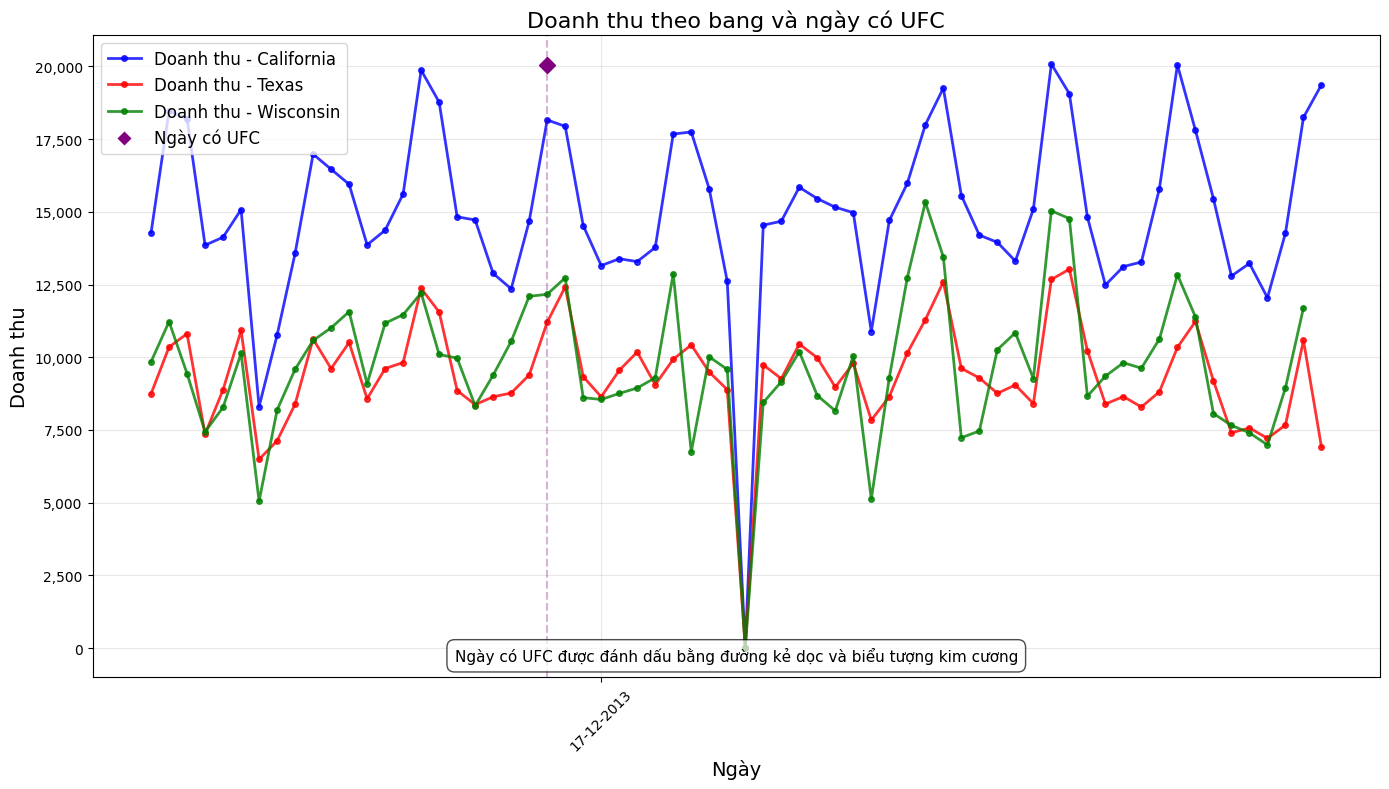

In [13]:
# Lấy ngày có UFC (flag_ufc = 1)
ufc_days = df.loc[df['flag_ufc'] == 1, 'date'].unique()

# Tạo figure
fig, ax = plt.subplots(figsize=(14, 8))

# Màu sắc cho các đường doanh thu của từng bang
colors = ['blue', 'red', 'green']

# Vẽ đường doanh thu cho mỗi bang
for i, state in enumerate(daily_revenue_by_state.columns):
    ax.plot(
        daily_revenue_by_state.index, 
        daily_revenue_by_state[state],
        color=colors[i],
        marker='o',
        markersize=4,
        linewidth=2,
        alpha=0.8,
        label=f'Doanh thu - {state}'
    )

# Đánh dấu những ngày có UFC
for date in ufc_days:
    # Vẽ một vùng tô màu dọc tại ngày có UFC
    ax.axvline(x=date, color='purple', alpha=0.3, linestyle='--', linewidth=1.5)
    
    # Thêm một điểm nhỏ ở phía trên biểu đồ để đánh dấu ngày có UFC
    ymax = ax.get_ylim()[1]
    ax.plot(date, ymax * 0.95, 'D', color='purple', markersize=8)

# Chú thích riêng cho UFC
from matplotlib.lines import Line2D
ufc_legend = Line2D([0], [0], marker='D', color='w', markerfacecolor='purple', 
                    markersize=8, label='Ngày có UFC')
handles, labels = ax.get_legend_handles_labels()
handles.append(ufc_legend)
ax.legend(handles=handles, loc='upper left', frameon=True, fontsize=12)

# Định dạng trục x để hiển thị label cứ mỗi 50 ngày
ax.xaxis.set_major_locator(mdates.DayLocator(interval=50))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%m-%Y'))
plt.xticks(rotation=45)

# Đặt tiêu đề và nhãn
ax.set_title('Doanh thu theo bang và ngày có UFC', fontsize=16)
ax.set_xlabel('Ngày', fontsize=14)
ax.set_ylabel('Doanh thu', fontsize=14)

# Định dạng số lớn hơn với dấu phẩy ngăn cách hàng nghìn
def thousands_formatter(x, pos):
    return f'{int(x):,}'

ax.yaxis.set_major_formatter(FuncFormatter(thousands_formatter))

# Thêm lưới để dễ đọc
ax.grid(True, alpha=0.3)

# Thêm văn bản chú thích
ax.annotate(
    'Ngày có UFC được đánh dấu bằng đường kẻ dọc và biểu tượng kim cương',
    xy=(0.5, 0.02),
    xycoords='axes fraction',
    ha='center',
    va='bottom',
    fontsize=11,
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.7)
)

plt.tight_layout()
plt.show()

## 🌪 3. Ngày diễn ra thiên tai
### Giả định ảnh hưởng:

- Trước thiên tai (như bão, lốc xoáy, cháy rừng), người dân thường tăng mua hàng thiết yếu: nước, đồ hộp, nến, pin, thuốc.

- Sau thiên tai, có thể doanh số giảm tạm thời nếu giao thông, điện bị gián đoạn.

In [21]:
df = pd.read_parquet('../../data/train_val.parquet').head(7500000)

c:\Users\Admin\anaconda3\envs\GPU\lib\site-packages\matplotlib\backends\backend_agg.py:240: RuntimeWarning: Glyph 10060 missing from current font.
  font.set_text(s, 0.0, flags=flags)
c:\Users\Admin\anaconda3\envs\GPU\lib\site-packages\matplotlib\backends\backend_agg.py:203: RuntimeWarning: Glyph 10060 missing from current font.
  font.set_text(s, 0, flags=flags)


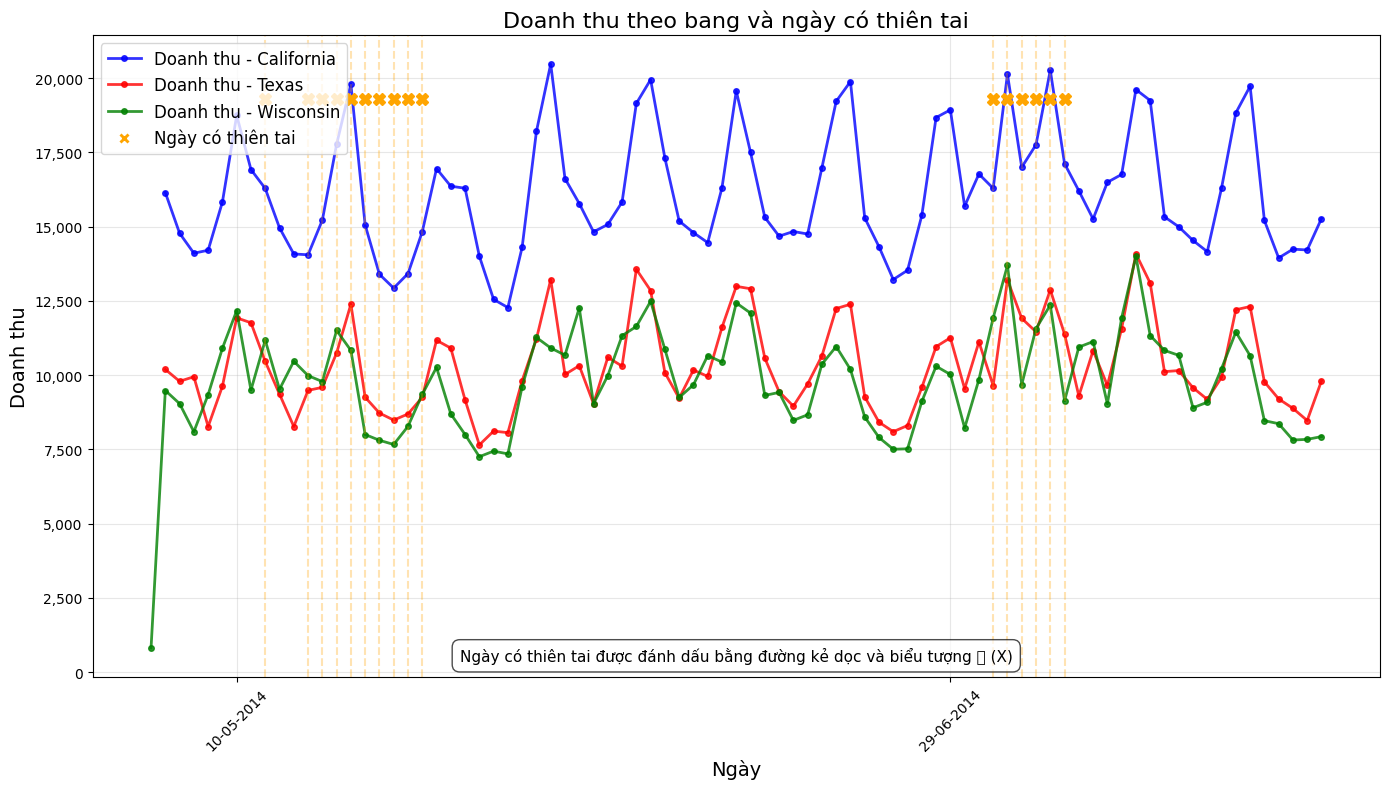

In [ ]:
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from matplotlib.lines import Line2D

df = df[:][5000000:7500000]

# Chuyển đổi state_id sang tên bang
state_mapping = {
    1: 'California',
    2: 'Texas',
    3: 'Wisconsin'
}

# Thêm cột state_name vào DataFrame
df['state_name'] = df['state_id'].map(state_mapping)

# Tạo figure với 3 subplot dọc
fig, axes = plt.subplots(3, 1, figsize=(14, 15), sharex=True)

# Màu sắc cho các đường doanh thu
colors = {
    'California': 'blue',
    'Texas': 'red',
    'Wisconsin': 'green'
}

# Nhóm dữ liệu theo ngày và bang, tính tổng doanh thu
daily_revenue_by_state = df.groupby(['date', 'state_name'])['demand'].sum().unstack()

# Vẽ biểu đồ cho từng bang riêng biệt
for i, state in enumerate(state_mapping.values()):
    ax = axes[i]
    
    # Vẽ đường doanh thu cho bang hiện tại
    if state in daily_revenue_by_state.columns:
        ax.plot(
            daily_revenue_by_state.index,
            daily_revenue_by_state[state],
            color=colors[state],
            marker='o',
            markersize=4,
            linewidth=2,
            alpha=0.8,
            label=f'Doanh thu - {state}'
        )
    
    # Lấy các ngày có thiên tai CHỈ của bang này
    disaster_days = df[(df['state_name'] == state) & (df['disaster_severity_flag'] != 0)]['date'].unique()
    
    # Đánh dấu những ngày có thiên tai chỉ của bang này
    for date in disaster_days:
        ax.axvline(x=date, color='orange', alpha=0.3, linestyle='--', linewidth=1.5)
        ymax = ax.get_ylim()[1]
        ax.plot(date, ymax * 0.9, 'X', color='orange', markersize=8)
    
    # Thêm chú thích
    disaster_legend = Line2D([0], [0], marker='X', color='w', markerfacecolor='orange',
                             markersize=8, label='Ngày có thiên tai')
    handles, labels = ax.get_legend_handles_labels()
    handles.append(disaster_legend)
    ax.legend(handles=handles, loc='upper left', frameon=True, fontsize=10)
    
    # Định dạng trục y - doanh thu
    def thousands_formatter(x, pos):
        return f'{int(x):,}'
    ax.yaxis.set_major_formatter(FuncFormatter(thousands_formatter))
    
    # Tiêu đề và nhãn
    ax.set_title(f'Doanh thu và ngày có thiên tai ở {state}', fontsize=14)
    ax.set_ylabel('Doanh thu', fontsize=12)
    
    # Lưới
    ax.grid(True, alpha=0.3)
    
    # Thêm số đếm thiên tai
    ax.annotate(
        f'Số ngày có thiên tai: {len(disaster_days)}',
        xy=(0.02, 0.02),
        xycoords='axes fraction',
        ha='left',
        va='bottom',
        fontsize=10,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7)
    )

# Định dạng trục x chung
axes[-1].xaxis.set_major_locator(mdates.DayLocator(interval=50))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%d-%m-%Y'))
axes[-1].set_xlabel('Ngày', fontsize=12)
plt.xticks(rotation=45)

# Tiêu đề chung
fig.suptitle('So sánh doanh thu và thiên tai theo từng bang', fontsize=16, y=0.99)

# Chú thích dưới biểu đồ
fig.text(
    0.5, 0.01,
    'Ngày có thiên tai được đánh dấu bằng đường kẻ dọc và biểu tượng ❌ (X)',
    ha='center',
    va='bottom',
    fontsize=11,
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.7)
)

plt.tight_layout()
plt.subplots_adjust(top=0.95, bottom=0.08)
plt.show()

## Độ ẩm

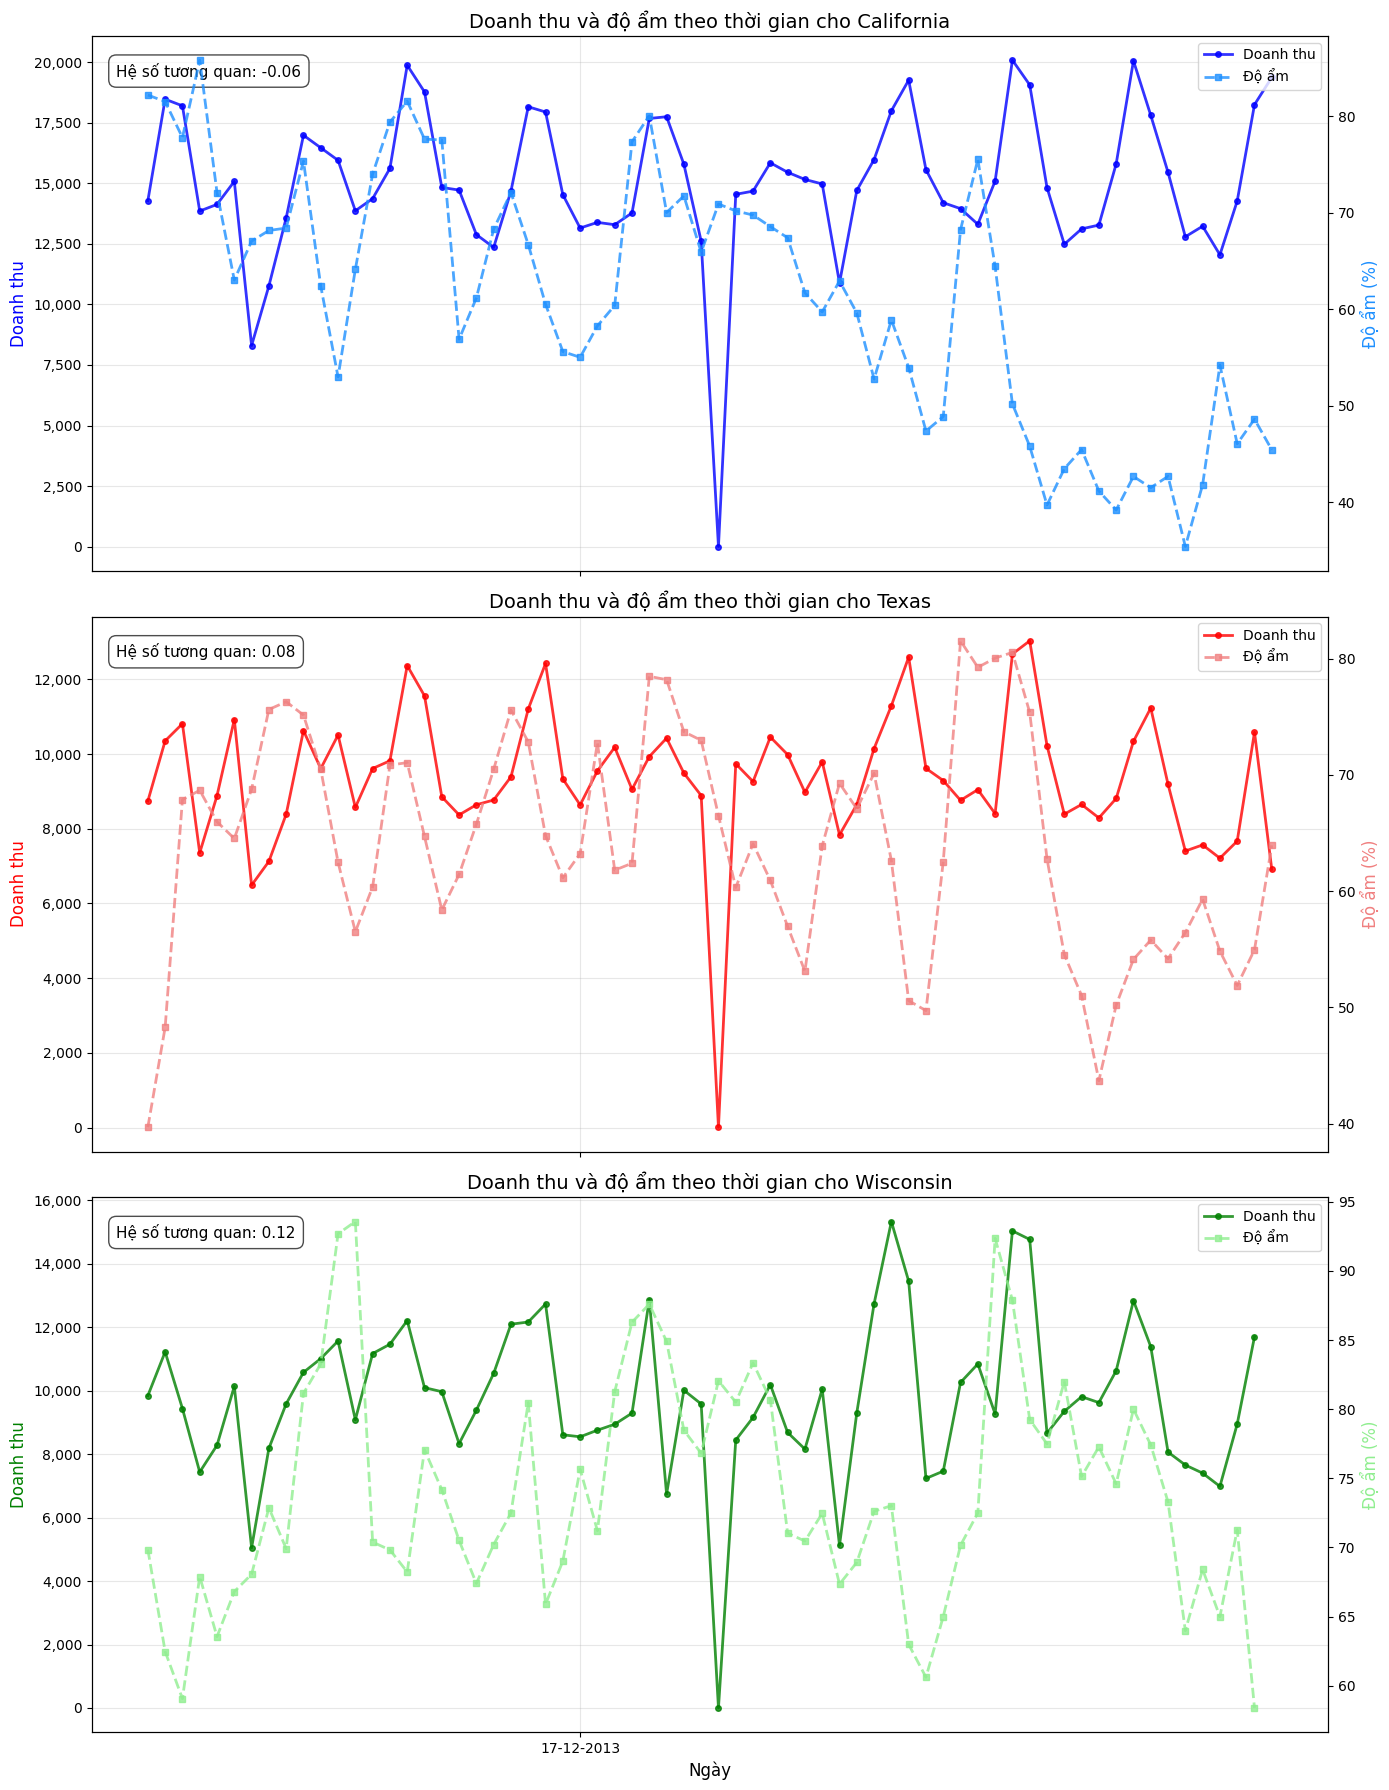

In [15]:
# Chuyển đổi state_id sang tên bang
state_mapping = {
    1: 'California',
    2: 'Texas',
    3: 'Wisconsin'
}

# Thêm cột state_name vào DataFrame
df['state_name'] = df['state_id'].map(state_mapping)

# Chuyển đổi cột ngày sang định dạng datetime nếu chưa phải
df['date'] = pd.to_datetime(df['date'])

# Nhóm dữ liệu theo ngày và bang, tính tổng doanh thu cho tất cả sản phẩm
daily_revenue_by_state = df.groupby(['date', 'state_name'])['demand'].sum().unstack()

# Nhóm dữ liệu theo ngày và bang để lấy độ ẩm riêng cho từng bang
humidity_by_state = df.groupby(['date', 'state_name'])['humidity'].mean().unstack()

# Tạo figure với 3 subplot, mỗi subplot cho một bang
fig, axes = plt.subplots(3, 1, figsize=(14, 18), sharex=True)

# Màu sắc cho các đường
colors_revenue = ['blue', 'red', 'green']
colors_humidity = ['dodgerblue', 'lightcoral', 'lightgreen']

# Xử lý từng bang
for i, state in enumerate(daily_revenue_by_state.columns):
    # Tạo trục y thứ hai cho độ ẩm
    ax1 = axes[i]
    ax2 = ax1.twinx()
    
    # Vẽ đường doanh thu
    ax1.plot(
        daily_revenue_by_state.index, 
        daily_revenue_by_state[state],
        color=colors_revenue[i],
        marker='o',
        markersize=4,
        linewidth=2,
        alpha=0.8,
        label=f'Doanh thu'
    )
    
    # Vẽ đường độ ẩm
    ax2.plot(
        humidity_by_state.index,
        humidity_by_state[state],
        color=colors_humidity[i],
        marker='s',
        markersize=4,
        linewidth=2,
        linestyle='--',
        alpha=0.8,
        label=f'Độ ẩm'
    )
    
    # Đặt tiêu đề và nhãn
    ax1.set_title(f'Doanh thu và độ ẩm theo thời gian cho {state}', fontsize=14)
    ax1.set_ylabel('Doanh thu', fontsize=12, color=colors_revenue[i])
    ax2.set_ylabel('Độ ẩm (%)', fontsize=12, color=colors_humidity[i])
    
    # Tính và hiển thị hệ số tương quan
    state_data = pd.DataFrame({
        'revenue': daily_revenue_by_state[state],
        'humidity': humidity_by_state[state]
    }).dropna()
    
    corr = state_data['revenue'].corr(state_data['humidity'])
    ax1.annotate(
        f'Hệ số tương quan: {corr:.2f}',
        xy=(0.02, 0.95),
        xycoords='axes fraction',
        va='top',
        ha='left',
        fontsize=11,
        bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.7)
    )
    
    # Định dạng số lớn hơn với dấu phẩy ngăn cách hàng nghìn
    def thousands_formatter(x, pos):
        return f'{int(x):,}'
    
    ax1.yaxis.set_major_formatter(FuncFormatter(thousands_formatter))
    
    # Kết hợp legends từ cả hai trục
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right', frameon=True, fontsize=10)
    
    # Thêm lưới để dễ đọc
    ax1.grid(True, alpha=0.3)

# Định dạng trục x để hiển thị label cứ mỗi 50 ngày
axes[2].xaxis.set_major_locator(mdates.DayLocator(interval=50))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%d-%m-%Y'))
axes[2].set_xlabel('Ngày', fontsize=12)

# Xoay nhãn trục x để dễ đọc
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## Train bằng LGB và tìm kiếm các feature quan trọng

In [ ]:
del df
gc.collect()
df = pd.read_parquet('../data/train_val.parquet')
df = df.drop(['date','disaster_type'],axis=1)

In [ ]:
def downcast(df):
    cols = df.dtypes.index.tolist()
    types = df.dtypes.values.tolist()
    
    for i, t in enumerate(types):
        col = cols[i]
        if 'int' in str(t):
            c_min = df[col].min()
            c_max = df[col].max()
            if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                df[col] = df[col].astype(np.int8)
            elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                df[col] = df[col].astype(np.int16)
            elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                df[col] = df[col].astype(np.int32)
            else:
                df[col] = df[col].astype(np.int64)

        elif 'float' in str(t):
            c_min = df[col].min()
            c_max = df[col].max()
            # ⚠️ Không dùng float16 vì không lưu được trong Parquet
            if c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                df[col] = df[col].astype(np.float32)
            else:
                df[col] = df[col].astype(np.float64)    
    return df

df = downcast(df)

In [ ]:
sample_submission = pd.read_csv('../data/sample_submission.csv')
sample_submission = downcast(sample_submission)

LAGS = [7, 28]
WINDOWS = [7, 28]
FIRST = 1942 # first to predict
LENGTH = 28

def demand_features_eval(df):
    """ Same as demand_features but for the step-by-step evaluation """
    out = df.groupby('id', sort=False).last()
    for lag in LAGS:
        out[f'lag_t{lag}'] = df.groupby('id', sort=False)['demand'].nth(-lag-1).astype("float32")
        for w in WINDOWS:
            out[f'rolling_mean_lag{lag}_w{w}'] = df.groupby('id', sort=False)['demand'].nth(list(range(-lag-w, -lag))).groupby('id', sort=False).mean().astype("float32")
    
    return out.reset_index()

def prep_train(df,drop_d = 1000):
    
    x = list(set(df.columns) - {'id', 'd', 'demand'})
    print(x)
    # Split into test, valid, train
    test = df[df.d >= FIRST - max(LAGS) - max(WINDOWS) - 28]
    df = df[df.d < FIRST]

    xtrain, xvalid, ytrain, yvalid = train_test_split(df[x], df["demand"], test_size=0.1, shuffle=True, random_state=54)
    train = lgb.Dataset(xtrain, label = ytrain)
    valid = lgb.Dataset(xvalid, label = yvalid)
    return train, valid, test, x

def fit_model(train, valid, num_r):
    """ Fit LightGBM model """
    
    params = {
        'metric': 'rmse',
        'objective': 'poisson',
        'seed': 200,
        'force_row_wise': True,
        'boosting_type': 'gbdt',
        'learning_rate': 0.015,
        'lambda': 0.1,
        'num_leaves': 63,
        'sub_row': 0.7,
        'bagging_freq': 1,
        'colsample_bytree': 0.7
    }

    callbacks = [
        early_stopping(stopping_rounds=200),
        log_evaluation(period=100)
    ]

    fit = lgb.train(params,
                    train,
                    num_boost_round=num_r,
                    valid_sets=[valid],
                    callbacks=callbacks)

    lgb.plot_importance(fit, importance_type="gain", precision=0, height=0.5, figsize=(6, 10))
    plt.show()

    return fit


def pred_all(fit, test, x):
    """ Calculate predictions """
    
    # Recursive prediction
    for i, day in enumerate(np.arange(FIRST, FIRST + LENGTH)):
        test_day = demand_features_eval(test[(test.d <= day) & (test.d >= day - max(LAGS) - max(WINDOWS))])
        test.loc[test.d == day, "demand"] = fit.predict(test_day[x])
    
    return test

def pred_to_csv(test, cols=sample_submission.columns, file="submission.csv"):
    """ Reshape predictions and save submission csv """
     
    # Prepare for reshaping
    test = test.assign(id=test.id + "_" + np.where(test.d < FIRST, "validation", "evaluation"),
                       F="F" + (test.d - FIRST + LENGTH + 1 - LENGTH * (test.d >= FIRST)).astype("str"))
    
    # Reshape
    submission = test.pivot(index="id", columns="F", values="demand").reset_index()[cols].fillna(1)
    
    # Export
    submission.to_csv(file, index=False)
    
    return True

train, valid, test, x = prep_train(df, 1000 - 28)

del df
gc.collect()

In [ ]:
def fit_model(train, valid, num_r):
    """ Fit LightGBM model """
    
    params = {
        'metric': 'rmse',
        'objective': 'poisson',
        'seed': 200,
        'force_row_wise': True,
        'boosting_type': 'gbdt',
        'learning_rate': 0.015,
        'lambda': 0.1,
        'num_leaves': 63,
        'sub_row': 0.7,
        'bagging_freq': 1,
        'colsample_bytree': 0.7
    }

    callbacks = [
        early_stopping(stopping_rounds=200),
        log_evaluation(period=100)
    ]

    fit = lgb.train(params,
                    train,
                    num_boost_round=num_r,
                    valid_sets=[valid],
                    callbacks=callbacks)

    lgb.plot_importance(fit, importance_type="gain", precision=0, height=0.5, figsize=(6, 10))
    plt.show()

    return fit


fit = fit_model(train, valid,100)
pred = pred_all(fit, test, x)
pred_to_csv(pred, cols=sample_submission.columns, file="../submission.csv")

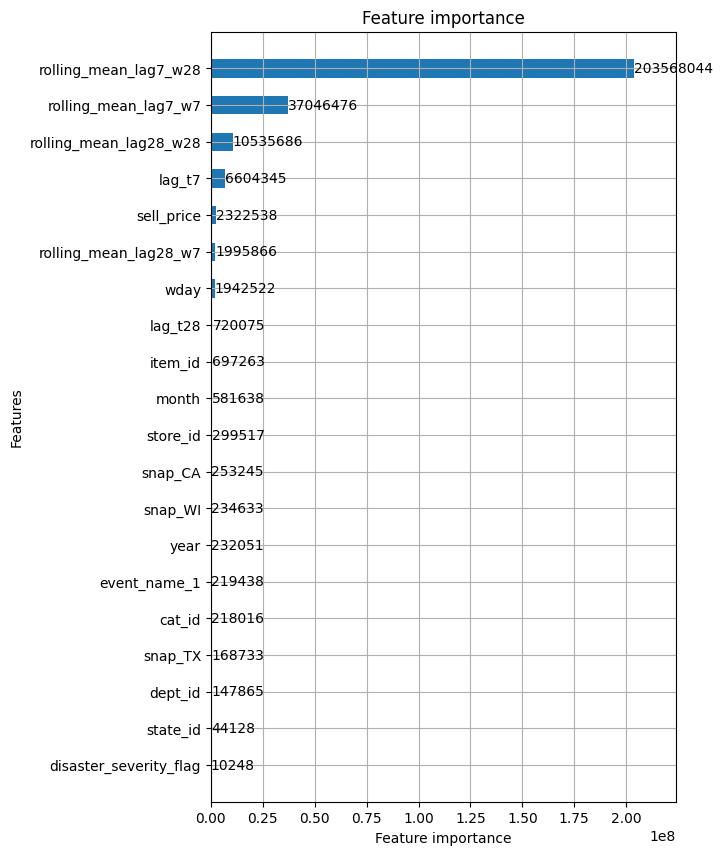